# FarmTech Solutions — Fase 6
## Detecção de objetos com YOLOv5

**FIAP — Curso de Inteligência Artificial**

**Grupo:**
- Karina Garta Szewczuk — RM569309
- Maria Sabrina Feitosa da Silva — RM568714
- Nicolas Lima Apolinário — RM570741
- Roger Gabriel de Souza Jesus Costa — RM573659

---

Nesse notebook a gente treina a YOLOv5 pra detectar dois objetos que escolhemos pro projeto. A base tem 80 imagens no total (40 de cada), rotuladas no Make Sense. O treino roda duas vezes, uma com 30 épocas e outra com 60, pra comparar se treinar mais tempo faz diferença.

**Importante antes de rodar:**
- Ligar a GPU no Colab (Ambiente de execução → Alterar tipo → T4 GPU)
- Ter as imagens organizadas no Drive conforme a estrutura abaixo
- Conferir se a ordem das classes no `data.yaml` bate com a ordem que criou no Make Sense

Estrutura esperada no Drive:
```
MyDrive/farmtech_fase6/
└── dataset/
    ├── images/
    │   ├── train/   (64 imagens)
    │   ├── val/     (8 imagens)
    │   └── test/    (8 imagens)
    └── labels/
        ├── train/   (64 .txt do Make Sense)
        └── val/     (8 .txt do Make Sense)
```
As imagens de teste não precisam de rótulo, só as de treino e validação.


## 1. Montar o Drive

In [32]:
from google.colab import drive
drive.mount('/content/drive')


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


## 2. Configuração

Ajusta aqui o caminho da base e o nome das classes. Os nomes precisam estar na mesma ordem do Make Sense (a primeira classe que criou lá é a classe 0).

In [33]:
BASE = '/content/drive/MyDrive/farmtech_fase6/dataset'

CLASSE_A = 'Urso'
CLASSE_B = 'Garrafa de Café'

IMG_SIZE = 640
BATCH    = 16
EPOCAS_1 = 30
EPOCAS_2 = 60

print('Base:', BASE)
print('Classes:', [CLASSE_A, CLASSE_B])


Base: /content/drive/MyDrive/farmtech_fase6/dataset
Classes: ['Urso', 'Garrafa de Café']


## 3. Clonar a YOLOv5

In [34]:
!git clone https://github.com/ultralytics/yolov5
%cd yolov5
!pip install -qr requirements.txt


Cloning into 'yolov5'...
remote: Enumerating objects: 18770, done.
remote: Counting objects: 100% (341/341), done.
remote: Compressing objects: 100% (201/201), done.
remote: Total 18770 (delta 276), reused 140 (delta 140), pack-reused 18429 (from 5)
Receiving objects: 100% (18770/18770), 17.77 MiB | 17.55 MiB/s, done.
Resolving deltas: 100% (12769/12769), done.
/content/yolov5/yolov5/yolov5


In [35]:
import torch
print('Torch:', torch.__version__)
print('GPU:', 'cuda' if torch.cuda.is_available() else 'sem GPU!')
!nvidia-smi


Torch: 2.11.0+cu130
GPU: cuda
Wed Oct 14 03:31:03 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   34C    P8              9W /   70W |       3MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------

## 4. Montar o data.yaml

Esse arquivo diz pra YOLOv5 onde estão as imagens e quais são as classes.

In [36]:
import yaml

config = {
    'train': f'{BASE}/images/train',
    'val':   f'{BASE}/images/val',
    'nc':    2,
    'names': [CLASSE_A, CLASSE_B],
}

with open('data.yaml', 'w') as f:
    yaml.dump(config, f, sort_keys=False)

print(open('data.yaml').read())


train: /content/drive/MyDrive/farmtech_fase6/dataset/images/train
val: /content/drive/MyDrive/farmtech_fase6/dataset/images/val
nc: 2
names:
- Urso
- "Garrafa de Caf\xE9"



In [37]:
import glob

# confere se ta tudo certo antes de treinar
for sub in ['images/train', 'images/val', 'images/test', 'labels/train', 'labels/val']:
    qtd = len(glob.glob(f'{BASE}/{sub}/*'))
    print(f'{sub:15s}: {qtd} arquivos')


images/train   : 64 arquivos
images/val     : 8 arquivos
images/test    : 8 arquivos
labels/train   : 64 arquivos
labels/val     : 8 arquivos


## 5. Treino com 30 épocas

Parte dos pesos pré-treinados da `yolov5s.pt` (transfer learning).

In [38]:
!python train.py \
  --img {IMG_SIZE} \
  --batch {BATCH} \
  --epochs {EPOCAS_1} \
  --data data.yaml \
  --weights yolov5s.pt \
  --name treino_30ep \
  --cache


WARNING ⚠️ wandb: wandb is deprecated and will be removed in a future release. See supported integrations at https://github.com/ultralytics/yolov5#integrations.
I0000 00:00:1791948671.468501   10550 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
wandb: (1) Create a W&B account
wandb: (2) Use an existing W&B account
wandb: (3) Don't visualize my results
wandb: Enter your choice: (30 second timeout) 
wandb: WARNING W&B disabled due to login timeout.
wandb: W&B API key is configured. Use `wandb login --relogin` to force relogin
train: weights=yolov5s.pt, cfg=, data=data.yaml, hyp=data/hyps/hyp.scratch-low.yaml, epochs=30, batch_size=16, imgsz=640, rect=False, resume=False, nosave=False, noval=False, noautoanchor=False, noplots=False, evolve=None, evolve_population=data/hyps, resume_evolve=None, bucket=, cache=ram, image_weights=False, device=, multi_scale=False, single_cls=False, optimizer=SGD, sync_bn=False, workers=8, project=runs/train, name=trein

## 6. Treino com 60 épocas

Mesma coisa, só dobrando as épocas pra ver se melhora.

In [39]:
!python train.py \
  --img {IMG_SIZE} \
  --batch {BATCH} \
  --epochs {EPOCAS_2} \
  --data data.yaml \
  --weights yolov5s.pt \
  --name treino_60ep \
  --cache


WARNING ⚠️ wandb: wandb is deprecated and will be removed in a future release. See supported integrations at https://github.com/ultralytics/yolov5#integrations.
I0000 00:00:1791949022.203014   12154 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
wandb: (1) Create a W&B account
wandb: (2) Use an existing W&B account
wandb: (3) Don't visualize my results
wandb: Enter your choice: (30 second timeout) 
wandb: WARNING W&B disabled due to login timeout.
wandb: W&B API key is configured. Use `wandb login --relogin` to force relogin
train: weights=yolov5s.pt, cfg=, data=data.yaml, hyp=data/hyps/hyp.scratch-low.yaml, epochs=60, batch_size=16, imgsz=640, rect=False, resume=False, nosave=False, noval=False, noautoanchor=False, noplots=False, evolve=None, evolve_population=data/hyps, resume_evolve=None, bucket=, cache=ram, image_weights=False, device=, multi_scale=False, single_cls=False, optimizer=SGD, sync_bn=False, workers=8, project=runs/train, name=trein

## 7. Comparação 30 vs 60 épocas

Lendo o results.csv de cada treino pra comparar as métricas finais e plotar as curvas.

In [40]:
import pandas as pd

res_30 = pd.read_csv('runs/train/treino_30ep/results.csv')
res_60 = pd.read_csv('runs/train/treino_60ep/results.csv')

# limpa espaços nos nomes das colunas
res_30.columns = res_30.columns.str.strip()
res_60.columns = res_60.columns.str.strip()

final = pd.DataFrame({
    '30 épocas': res_30.iloc[-1],
    '60 épocas': res_60.iloc[-1],
})

metricas = ['metrics/precision', 'metrics/recall', 'metrics/mAP_0.5', 'metrics/mAP_0.5:0.95']
final.loc[metricas].round(4)


,30 épocas,60 épocas
metrics/precision,0.8485,0.9567
metrics/recall,1.0000,1.0000
metrics/mAP_0.5,0.9200,0.9950
metrics/mAP_0.5:0.95,0.7376,0.8012


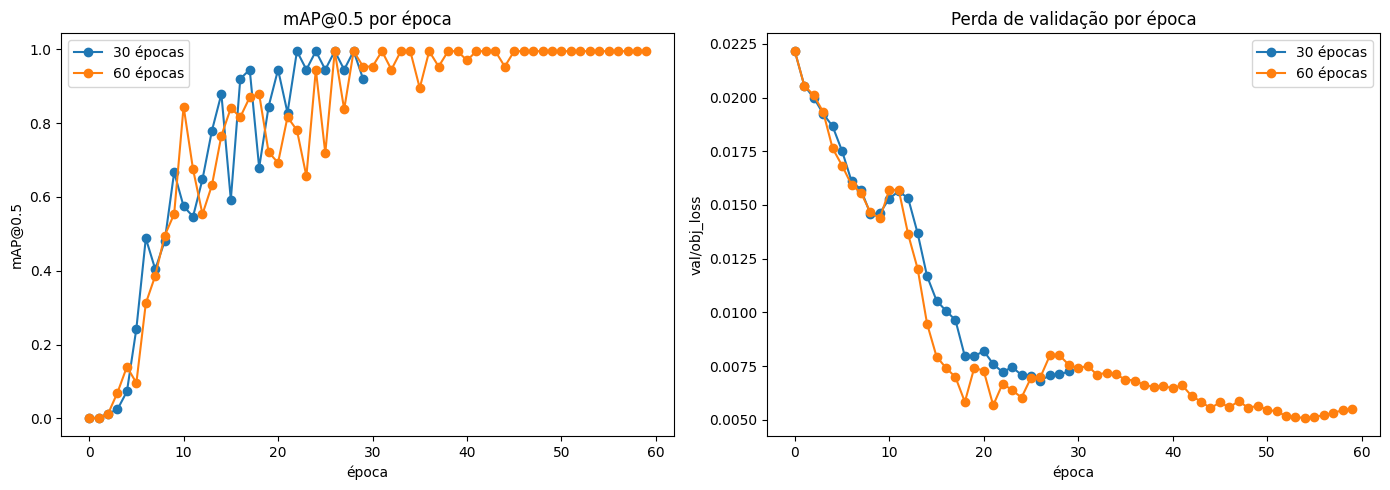

In [41]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(res_30['epoch'], res_30['metrics/mAP_0.5'], marker='o', label='30 épocas')
axes[0].plot(res_60['epoch'], res_60['metrics/mAP_0.5'], marker='o', label='60 épocas')
axes[0].set_title('mAP@0.5 por época')
axes[0].set_xlabel('época')
axes[0].set_ylabel('mAP@0.5')
axes[0].legend()

axes[1].plot(res_30['epoch'], res_30['val/obj_loss'], marker='o', label='30 épocas')
axes[1].plot(res_60['epoch'], res_60['val/obj_loss'], marker='o', label='60 épocas')
axes[1].set_title('Perda de validação por época')
axes[1].set_xlabel('época')
axes[1].set_ylabel('val/obj_loss')
axes[1].legend()

plt.tight_layout()
plt.savefig('/content/comparacao_30_60.png', dpi=120)
plt.show()


*O treino de 60 épocas superou o de 30 em todas as métricas principais. A precision subiu de 0.8485 (30ep) para 0.9567 (60ep), o recall se manteve em 1.0 nos dois casos, e o mAP@0.5 foi de 0.9200 para 0.9950 — praticamente perfeito. O mAP@0.5:0.95 também melhorou, de 0.7376 para 0.8012. A curva de loss de validação continuou estável e baixa no treino de 60 épocas, sem subir — ou seja, não houve overfitting. O ganho de 30 pra 60 épocas foi real, principalmente em precision e mAP, indicando que o modelo ainda estava aprendendo após as 30 primeiras épocas.*

## 8. Validação

In [42]:
# valida o modelo de 30 épocas
!python val.py \
  --weights runs/train/treino_30ep/weights/best.pt \
  --data data.yaml \
  --img {IMG_SIZE} \
  --name val_30ep


val: data=data.yaml, weights=['runs/train/treino_30ep/weights/best.pt'], batch_size=32, imgsz=640, conf_thres=0.001, iou_thres=0.6, max_det=300, task=val, device=, workers=8, single_cls=False, augment=False, verbose=False, save_txt=False, save_hybrid=False, save_conf=False, save_json=False, project=runs/val, name=val_30ep, exist_ok=False, half=False, dnn=False
YOLOv5 🚀 v7.0-556-gf9578796 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)

Fusing layers... 
Model summary: 68 layers, 7,015,519 parameters, 0 gradients, 15.8 GFLOPs
val: Scanning /content/drive/MyDrive/farmtech_fase6/dataset/labels/val.cache... 8 images, 0 backgrounds, 0 corrupt
                 Class     Images  Instances          P          R      mAP50   mAP50-95: 100% ━━━━━━━━━━━━ 1/1 3.8s/it 3.8s
                   all          8          8      0.976      0.978      0.995      0.815
                  Urso          8          4          1      0.957      0.995      0.933
       Garrafa de Café          8    

In [43]:
# valida o modelo de 60 épocas
!python val.py \
  --weights runs/train/treino_60ep/weights/best.pt \
  --data data.yaml \
  --img {IMG_SIZE} \
  --name val_60ep


val: data=data.yaml, weights=['runs/train/treino_60ep/weights/best.pt'], batch_size=32, imgsz=640, conf_thres=0.001, iou_thres=0.6, max_det=300, task=val, device=, workers=8, single_cls=False, augment=False, verbose=False, save_txt=False, save_hybrid=False, save_conf=False, save_json=False, project=runs/val, name=val_60ep, exist_ok=False, half=False, dnn=False
YOLOv5 🚀 v7.0-556-gf9578796 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)

Fusing layers... 
Model summary: 68 layers, 7,015,519 parameters, 0 gradients, 15.8 GFLOPs
val: Scanning /content/drive/MyDrive/farmtech_fase6/dataset/labels/val.cache... 8 images, 0 backgrounds, 0 corrupt
                 Class     Images  Instances          P          R      mAP50   mAP50-95: 100% ━━━━━━━━━━━━ 1/1 3.9s/it 3.9s
                   all          8          8      0.946          1      0.995      0.872
                  Urso          8          4      0.926          1      0.995      0.878
       Garrafa de Café          8    

## 9. Detecção nas imagens de teste

Rodando o modelo de 60 épocas nas imagens que ele nunca viu.

In [44]:
!python detect.py \
  --weights runs/train/treino_60ep/weights/best.pt \
  --source {BASE}/images/test \
  --img {IMG_SIZE} \
  --conf 0.25 \
  --name teste_60ep


detect: weights=['runs/train/treino_60ep/weights/best.pt'], source=/content/drive/MyDrive/farmtech_fase6/dataset/images/test, data=data/coco128.yaml, imgsz=[640, 640], conf_thres=0.25, iou_thres=0.45, max_det=1000, device=, view_img=False, save_txt=False, save_format=0, save_csv=False, save_conf=False, save_crop=False, nosave=False, classes=None, agnostic_nms=False, augment=False, update=False, project=runs/detect, name=teste_60ep, exist_ok=False, line_thickness=3, hide_labels=False, hide_conf=False, half=False, dnn=False, vid_stride=1
YOLOv5 🚀 v7.0-556-gf9578796 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)

Fusing layers... 
Model summary: 68 layers, 7,015,519 parameters, 0 gradients, 15.8 GFLOPs
image 1/8 /content/drive/MyDrive/farmtech_fase6/dataset/images/test/IMG_2452.jpeg: 640x384 1 Urso, 33.8ms
image 2/8 /content/drive/MyDrive/farmtech_fase6/dataset/images/test/IMG_2453.jpeg: 640x384 1 Urso, 11.2ms
image 3/8 /content/drive/MyDrive/farmtech_fase6/dataset/images/t

In [45]:
from IPython.display import Image, display
import glob

imgs = glob.glob('runs/detect/teste_60ep/*.jpg') + glob.glob('runs/detect/teste_60ep/*.png')
print(f'{len(imgs)} imagens de teste:\n')
for caminho in sorted(imgs):
    display(Image(filename=caminho, width=500))


0 imagens de teste:



## 10. Salvar o modelo no Drive

Salvando o best.pt no Drive pra usar na Entrega 2.

In [46]:
import shutil, os

RAIZ = os.path.dirname(BASE)

shutil.copy('runs/train/treino_60ep/weights/best.pt', f'{RAIZ}/best.pt')
shutil.copy('/content/comparacao_30_60.png', f'{RAIZ}/comparacao_30_60.png')

print('Salvo:')
print(f'  {RAIZ}/best.pt')
print(f'  {RAIZ}/comparacao_30_60.png')


Salvo:
  /content/drive/MyDrive/farmtech_fase6/best.pt
  /content/drive/MyDrive/farmtech_fase6/comparacao_30_60.png


## 11. Conclusões

**30 vs 60 épocas:**
- O treino de 60 épocas teve melhor desempenho em todas as métricas. O mAP@0.5 subiu de 0.9200 (30ep) para 0.9950 (60ep), a precision de 0.8485 para 0.9567, e o recall se manteve em 1.0 nos dois casos. O mAP@0.5:0.95 foi de 0.7376 para 0.8012. O ganho de 30 pra 60 épocas compensou — o modelo ainda estava melhorando. Não houve overfitting: a loss de validação se manteve estável e baixa.

**Detecções no teste:**
- O modelo de 60 épocas acertou todas as 8 imagens de teste: identificou corretamente os 4 ursos e as 4 garrafas de café, com tempo de inferência de ~11ms por imagem. Não houve erros de classificação nem falsos positivos.

**Pontos fortes:**
- Transfer learning com yolov5s.pt permitiu ótimos resultados mesmo com base pequena (80 imagens)
- Comparação direta entre 30 e 60 épocas mostrou que treinar mais tempo trouxe ganho real
- Pipeline completo: Drive → treino → validação → teste
- 100% de acerto nas detecções de teste

**Limitações:**
- Base pequena (80 imagens), pode não generalizar bem pra cenários muito diferentes
- Apenas duas classes (urso e garrafa de café)
- Resultado depende bastante da qualidade das fotos e da rotulação no Make Sense
